# Reliance mean-reversion study — CFA induction 2026
**Adrij Sarkar | Track 1**

This notebook retains the original baseline analysis and adds a complete
report-generation section. Run all cells in order. The repository price
snapshot reproduces the report without a new Yahoo download.

The baseline uses a 20-session sample-standard-deviation Z-score, entry below
-2 and exit at/above 0 at the next session's Open. The development period is
2016–2022; the original validation is a continuous-run slice in 2023; the
baseline final test is 2024. Exploratory analysis included validation data.

**Assistance:** ChatGPT/Codex helped with teaching, code drafting/debugging,
metrics, charts and the report. Review and understand every section before
submission; cite any other resources you used. See `docs/SOURCES.md`.

## Original analysis and baseline backtest


In [1]:
# Install only dependencies absent from this notebook environment.
import importlib.util
import subprocess
import sys
packages = ['yfinance', 'pandas', 'numpy', 'matplotlib', 'reportlab']
missing = [name for name in packages if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
print('Notebook dependencies are available.')

Notebook dependencies are available.


In [2]:
import pandas as pd
import yfinance as yf

ticker = "RELIANCE.NS"

from pathlib import Path
project_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
snapshot_paths = [project_root / 'data/reliance_prices.csv', Path.cwd() / 'reliance_prices.csv']
snapshot = next((path for path in snapshot_paths if path.exists()), None)
if snapshot is not None:
    data = pd.read_csv(snapshot, index_col=0, parse_dates=True)
    print('Using saved price snapshot:', snapshot)
else:
    data = yf.download(ticker, start='2016-01-01', end='2025-01-01',
                       interval='1d', auto_adjust=True, actions=True,
                       progress=False, multi_level_index=False)

if data.empty:
    raise RuntimeError("No data downloaded. Try again later or use the NSE archive.")

# Handle yfinance versions that return multi-level columns
if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)

required_columns = ["Open", "High", "Low", "Close", "Volume"]
missing_columns = [c for c in required_columns if c not in data.columns]
if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")

print("Rows and columns:", data.shape)
print("Date range:", data.index.min().date(), "to", data.index.max().date())
print("Columns:", list(data.columns))
print("\nMissing values:\n", data[required_columns].isna().sum())
print("Duplicate dates:", data.index.duplicated().sum())
print("Non-positive prices:",
      (data[["Open", "High", "Low", "Close"]] <= 0).sum().to_dict())
print("Zero-volume days:", (data["Volume"] == 0).sum())
print("\nFirst five rows:\n", data[required_columns].head())

Using saved price snapshot: /workspace/scratch/cab299e362b3/quant-completion/CFA-INDUCTION-main/data/reliance_prices.csv
Rows and columns: (2221, 7)
Date range: 2016-01-01 to 2024-12-31
Columns: ['Close', 'Dividends', 'High', 'Low', 'Open', 'Stock Splits', 'Volume']

Missing values:
 Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64
Duplicate dates: 0
Non-positive prices: {'Open': 0, 'High': 0, 'Low': 0, 'Close': 0}
Zero-volume days: 0

First five rows:
                   Open        High         Low       Close    Volume
Date                                                                
2016-01-01  217.800412  219.763163  217.455323  218.997482   5416562
2016-01-04  216.765102  218.663148  212.818033  214.672943  30170947
2016-01-05  215.751391  217.843550  215.039631  216.797470  14946239
2016-01-06  217.325876  223.969037  215.772933  222.631775  26759864
2016-01-07  220.226876  221.725899  217.422958  218.544525  19739943


In [3]:
development = data.loc["2016-01-01":"2022-12-31"]
validation = data.loc["2023-01-01":"2023-12-31"]
final_test = data.loc["2024-01-01":"2024-12-31"]

print("Development rows:", len(development))
print("Validation rows:", len(validation))
print("Final test rows:", len(final_test))

Development rows: 1730
Validation rows: 245
Final test rows: 246


Daily return summary:
count    1974.0000
mean        0.0011
std         0.0178
min        -0.1315
25%        -0.0085
50%         0.0009
75%         0.0101
max         0.1472
Name: Daily Return, dtype: float64

Five largest daily moves:
            Absolute return  Signed return
Date                                      
2020-03-25           0.1472         0.1472
2020-03-23           0.1315        -0.1315
2020-03-09           0.1234        -0.1234
2020-04-07           0.1194         0.1194
2017-02-22           0.1096         0.1096


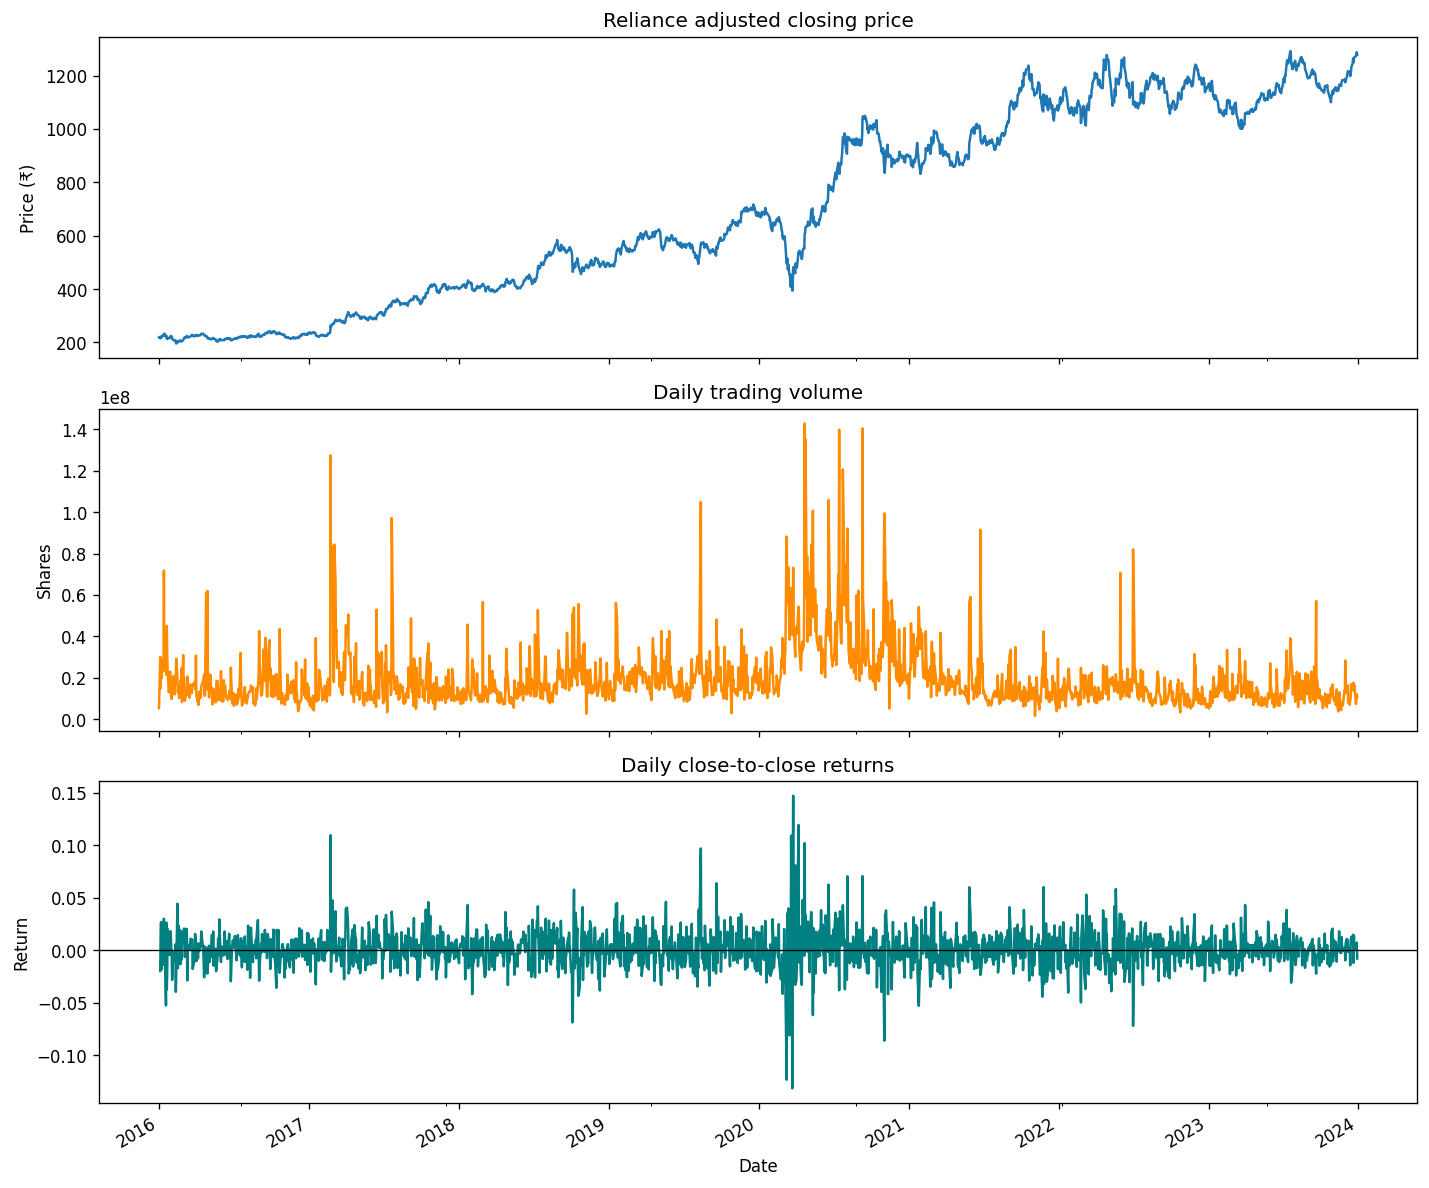

In [4]:
import matplotlib.pyplot as plt

# Use development + validation data only; keep 2024 reserved
analysis = data.loc[:"2023-12-31"].copy()
analysis["Daily Return"] = analysis["Close"].pct_change()

print("Daily return summary:")
print(analysis["Daily Return"].describe().round(4))

print("\nFive largest daily moves:")
print(
    analysis["Daily Return"]
    .abs()
    .nlargest(5)
    .rename("Absolute return")
    .to_frame()
    .join(analysis["Daily Return"].rename("Signed return"))
    .round(4)
)

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

analysis["Close"].plot(ax=axes[0], title="Reliance adjusted closing price")
axes[0].set_ylabel("Price (₹)")

analysis["Volume"].plot(ax=axes[1], color="darkorange",
                        title="Daily trading volume")
axes[1].set_ylabel("Shares")

analysis["Daily Return"].plot(ax=axes[2], color="teal",
                              title="Daily close-to-close returns")
axes[2].set_ylabel("Return")
axes[2].axhline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()

In [5]:
extreme_dates = analysis["Daily Return"].abs().nlargest(5).index

columns_to_show = [
    "Open", "High", "Low", "Close", "Volume",
    "Dividends", "Stock Splits"
]

for date in extreme_dates:
    start = date - pd.Timedelta(days=3)
    end = date + pd.Timedelta(days=3)

    print(f"\nAround {date.date()}:")
    print(
        data.loc[start:end, columns_to_show]
        .round(2)
        .to_string()
    )


Around 2020-03-25:
              Open    High     Low   Close    Volume  Dividends  Stock Splits
Date                                                                         
2020-03-23  407.98  423.03  389.92  393.66  40670949        0.0           0.0
2020-03-24  414.12  431.94  398.89  420.09  45734887        0.0           0.0
2020-03-25  429.17  512.78  428.93  481.92  73130298        0.0           0.0
2020-03-26  487.95  497.35  464.15  474.77  45744488        0.0           0.0
2020-03-27  487.60  493.07  465.87  474.51  41657940        0.0           0.0

Around 2020-03-23:
              Open    High     Low   Close    Volume  Dividends  Stock Splits
Date                                                                         
2020-03-20  418.35  460.84  414.12  453.29  63360475        0.0           0.0
2020-03-23  407.98  423.03  389.92  393.66  40670949        0.0           0.0
2020-03-24  414.12  431.94  398.89  420.09  45734887        0.0           0.0
2020-03-25  429.17  512.

In [6]:
# Work through validation only; keep the final-test year reserved
signals = data.loc[:"2023-12-31"].copy()

window = 20
signals["Rolling_Mean"] = signals["Close"].rolling(window).mean()
signals["Rolling_Std"] = signals["Close"].rolling(window).std()
signals["Z_Score"] = (
    (signals["Close"] - signals["Rolling_Mean"])
    / signals["Rolling_Std"]
)

# Candidate conditions, detected using today's close
signals["Entry_Candidate"] = signals["Z_Score"] < -2
signals["Exit_Candidate"] = signals["Z_Score"] >= 0

print("Rows with a calculated Z-score:",
      signals["Z_Score"].notna().sum())
print("Entry candidate days:",
      signals["Entry_Candidate"].sum())
print("Exit candidate days:",
      signals["Exit_Candidate"].sum())

print("\nLatest candidate signals:")
print(
    signals.loc[
        signals["Entry_Candidate"] | signals["Exit_Candidate"],
        ["Close", "Z_Score", "Entry_Candidate", "Exit_Candidate"]
    ].tail(10).round(3)
)

Rows with a calculated Z-score: 1956
Entry candidate days: 85
Exit candidate days: 1105

Latest candidate signals:
               Close  Z_Score  Entry_Candidate  Exit_Candidate
Date                                                          
2023-12-15  1232.932    1.965            False            True
2023-12-18  1245.480    2.196            False            True
2023-12-19  1263.809    2.491            False            True
2023-12-20  1248.519    1.640            False            True
2023-12-21  1266.008    1.975            False            True
2023-12-22  1267.243    1.752            False            True
2023-12-26  1273.666    1.719            False            True
2023-12-27  1278.013    1.639            False            True
2023-12-28  1287.252    1.690            False            True
2023-12-29  1277.074    1.279            False            True


In [7]:
from math import floor
import pandas as pd

bt = data.loc[:"2023-12-31"].copy()

window = 20
entry_threshold = -2
exit_threshold = 0

initial_capital = 100_000
allocation_fraction = 0.10
slippage_rate = 0.0005  # example: 0.05% per side
cost_rate = 0.001       # example: 0.10% per side

bt["Z_Score"] = (
    (bt["Close"] - bt["Close"].rolling(window).mean())
    / bt["Close"].rolling(window).std()
)

cash = initial_capital
quantity = 0
pending_order = None
entry = None
trade_log = []

for i in range(window - 1, len(bt)):
    date = bt.index[i]

    # Fill the previous session's signal at today's open
    if pending_order is not None:
        if pending_order["side"] == "BUY":
            entry_fill = bt["Open"].iloc[i] * (1 + slippage_rate)
            quantity = floor(
                cash * allocation_fraction
                / (entry_fill * (1 + cost_rate))
            )

            if quantity > 0:
                entry_value = quantity * entry_fill
                entry_fee = entry_value * cost_rate
                cash -= entry_value + entry_fee

                entry = {
                    "signal_date": pending_order["signal_date"],
                    "fill_date": date,
                    "fill_price": entry_fill,
                    "fee": entry_fee,
                    "quantity": quantity,
                    "fill_index": i,
                }

        elif pending_order["side"] == "SELL" and quantity > 0:
            exit_fill = bt["Open"].iloc[i] * (1 - slippage_rate)
            exit_value = quantity * exit_fill
            exit_fee = exit_value * cost_rate
            cash += exit_value - exit_fee

            net_pnl = (
                exit_value - exit_fee
                - (entry["quantity"] * entry["fill_price"] + entry["fee"])
            )

            trade_log.append({
                "entry_signal_date": entry["signal_date"],
                "entry_fill_date": entry["fill_date"],
                "exit_signal_date": pending_order["signal_date"],
                "exit_fill_date": date,
                "quantity": quantity,
                "entry_fill": round(entry["fill_price"], 2),
                "exit_fill": round(exit_fill, 2),
                "entry_fee": round(entry["fee"], 2),
                "exit_fee": round(exit_fee, 2),
                "net_pnl": net_pnl,
                "holding_sessions": i - entry["fill_index"],
            })

            quantity = 0
            entry = None

        pending_order = None

    # Today's close creates an order for the next session
    z = bt["Z_Score"].iloc[i]

    if pd.notna(z):
        if quantity == 0 and z < entry_threshold:
            pending_order = {"side": "BUY", "signal_date": date}

        elif quantity > 0 and z >= exit_threshold:
            pending_order = {"side": "SELL", "signal_date": date}

trades = pd.DataFrame(trade_log)

print("Completed trades:", len(trades))
print("Ending cash:", round(cash, 2))
print(trades.head())

Completed trades: 30
Ending cash: 103073.12
  entry_signal_date entry_fill_date  ...     net_pnl holding_sessions
0        2016-02-11      2016-02-12  ...  295.416385               12
1        2016-04-28      2016-04-29  ... -200.713349               21
2        2016-11-02      2016-11-03  ... -297.313784               20
3        2017-01-18      2017-01-19  ...  140.288314               18
4        2017-05-05      2017-05-08  ...  162.196716               16

[5 rows x 11 columns]


In [8]:
last_close = bt["Close"].iloc[-1]
marked_equity = cash + quantity * last_close

print("Completed trades:", len(trades))
print("Realized net P&L:", round(trades["net_pnl"].sum(), 2))
print("Ending cash:", round(cash, 2))
print("Shares still held:", quantity)
print("Last close:", round(last_close, 2))
print("Portfolio value at last close:", round(marked_equity, 2))

if quantity > 0:
    open_pnl_before_exit_costs = (
        quantity * last_close
        - (quantity * entry["fill_price"] + entry["fee"])
    )
    print("Open-position P&L before exit costs:",
          round(open_pnl_before_exit_costs, 2))
    print("Open trade details:", entry)

if pending_order is not None:
    print("Unfilled order at end of data:", pending_order)

Completed trades: 30
Realized net P&L: 3073.12
Ending cash: 103073.12
Shares still held: 0
Last close: 1277.07
Portfolio value at last close: 103073.12


In [9]:
import numpy as np
import pandas as pd

# --- Strategy and execution assumptions ---
initial_cash = 100_000
position_fraction = 0.10
entry_threshold = -2.0
exit_threshold = 0.0
slippage_rate = 0.0005       # 0.05% each side
transaction_cost_rate = 0.001  # 0.10% each side

# Work on a sorted copy; dates must be the index.
bt = bt.sort_index().copy()

required_columns = {"Open", "Close"}
missing_columns = required_columns - set(bt.columns)
if missing_columns:
    raise ValueError(f"bt is missing required columns: {missing_columns}")

# Find the Z-score column, including common names like Z_score or rolling_zscore.
def normalize_name(name):
    return "".join(ch for ch in str(name).lower() if ch.isalnum())

z_candidates = [
    col for col in bt.columns
    if normalize_name(col) in {"z", "zscore"}
    or normalize_name(col).endswith("zscore")
]

if not z_candidates:
    raise ValueError(
        "Could not find the Z-score column. Check bt.columns and set z_col "
        "manually to your Z-score column name."
    )

z_col = z_candidates[0]
print("Using Z-score column:", z_col)

# --- Backtest state ---
cash = float(initial_cash)
shares = 0
entry_date = None
entry_fill_price = None
entry_cash_outlay = 0.0

trades = []
equity_records = []

# Record initial capital on the first date.
equity_records.append({
    "Date": bt.index[0],
    "Equity": cash
})

# Signals use the previous day's Z-score.
# Orders execute at today's Open, avoiding same-day lookahead.
for i in range(1, len(bt)):
    previous_z = bt[z_col].iloc[i - 1]
    today_open = bt["Open"].iloc[i]
    today_close = bt["Close"].iloc[i]

    # Exit an open position when the previous day's Z-score reaches 0.
    if shares > 0 and pd.notna(previous_z) and previous_z >= exit_threshold:
        exit_fill_price = today_open * (1 - slippage_rate)
        gross_sale = shares * exit_fill_price
        exit_fee = gross_sale * transaction_cost_rate
        net_sale_proceeds = gross_sale - exit_fee

        cash += net_sale_proceeds
        net_pnl = net_sale_proceeds - entry_cash_outlay

        trades.append({
            "Entry date": entry_date,
            "Exit date": bt.index[i],
            "Shares": shares,
            "Entry fill": entry_fill_price,
            "Exit fill": exit_fill_price,
            "Net P&L": net_pnl
        })

        shares = 0
        entry_date = None
        entry_fill_price = None
        entry_cash_outlay = 0.0

    # Enter when flat and the previous day's Z-score is below -2.
    elif shares == 0 and pd.notna(previous_z) and previous_z < entry_threshold:
        trade_budget = cash * position_fraction
        entry_fill_price = today_open * (1 + slippage_rate)

        # Integer shares; ensure the entry fee also fits within the budget.
        shares_to_buy = int(
            trade_budget
            / (entry_fill_price * (1 + transaction_cost_rate))
        )

        if shares_to_buy > 0:
            gross_purchase = shares_to_buy * entry_fill_price
            entry_fee = gross_purchase * transaction_cost_rate
            entry_cash_outlay = gross_purchase + entry_fee

            cash -= entry_cash_outlay
            shares = shares_to_buy
            entry_date = bt.index[i]

    # Record equity every day, after today's trade decision, marked at today's Close.
    equity_records.append({
        "Date": bt.index[i],
        "Equity": cash + shares * today_close,
        "Cash": cash,
        "Shares": shares
    })

# --- Build equity curve and calculate drawdown ---
equity_curve = pd.DataFrame(equity_records).set_index("Date")
equity_curve["Running peak"] = equity_curve["Equity"].cummax()
equity_curve["Drawdown"] = (
    equity_curve["Equity"] / equity_curve["Running peak"]
) - 1

# --- Matched-period buy-and-hold benchmark ---
start_date = equity_curve.index[0]
end_date = equity_curve.index[-1]

start_close = bt.loc[start_date, "Close"]
end_close = bt.loc[end_date, "Close"]

strategy_return = equity_curve["Equity"].iloc[-1] / initial_cash - 1
buy_hold_return = end_close / start_close - 1
max_drawdown = equity_curve["Drawdown"].min()

print(f"\nPeriod: {start_date.date()} to {end_date.date()}")
print(f"Equity rows: {len(equity_curve)}")
print(f"Distinct equity values: {equity_curve['Equity'].nunique()}")
print(f"Starting equity: ₹{initial_cash:,.2f}")
print(f"Ending equity: ₹{equity_curve['Equity'].iloc[-1]:,.2f}")
print(f"Strategy return: {strategy_return:.2%}")
print(f"Buy-and-hold return: {buy_hold_return:.2%}")
print(f"Maximum drawdown: {max_drawdown:.2%}")
print(f"Completed trades: {len(trades)}")

if trades:
    trades_df = pd.DataFrame(trades)
    print(f"Total realized trade P&L: ₹{trades_df['Net P&L'].sum():,.2f}")
else:
    trades_df = pd.DataFrame()
    print("No completed trades.")

if shares > 0:
    print(f"Open position at end: {shares} shares")
else:
    print("Open position at end: none")

Using Z-score column: Z_Score

Period: 2016-01-01 to 2023-12-29
Equity rows: 1975
Distinct equity values: 406
Starting equity: ₹100,000.00
Ending equity: ₹103,073.12
Strategy return: 3.07%
Buy-and-hold return: 483.15%
Maximum drawdown: -3.32%
Completed trades: 30
Total realized trade P&L: ₹3,073.12
Open position at end: none


In [10]:
years = (
    equity_curve.index[-1] - equity_curve.index[0]
).days / 365.25

strategy_cagr = (
    equity_curve["Equity"].iloc[-1] / initial_cash
) ** (1 / years) - 1

bh_close = bt.loc[equity_curve.index, "Close"]
bh_equity = initial_cash * bh_close / bh_close.iloc[0]
bh_drawdown = (bh_equity / bh_equity.cummax()) - 1
buy_hold_cagr = (
    bh_equity.iloc[-1] / bh_equity.iloc[0]
) ** (1 / years) - 1

market_value = (
    equity_curve["Shares"].fillna(0) * bh_close
)
average_exposure = (
    market_value / equity_curve["Equity"]
).mean()

print(f"Strategy CAGR:       {strategy_cagr:.2%}")
print(f"Buy-and-hold CAGR:   {buy_hold_cagr:.2%}")
print(f"Strategy max DD:     {equity_curve['Drawdown'].min():.2%}")
print(f"Buy-and-hold max DD: {bh_drawdown.min():.2%}")
print(f"Average exposure:    {average_exposure:.2%}")

Strategy CAGR:       0.38%
Buy-and-hold CAGR:   24.69%
Strategy max DD:     -3.32%
Buy-and-hold max DD: -45.09%
Average exposure:    1.81%


In [11]:
pnl = trades_df["Net P&L"]

gross_profit = pnl[pnl > 0].sum()
gross_loss = abs(pnl[pnl < 0].sum())
profit_factor = (
    gross_profit / gross_loss if gross_loss > 0 else float("inf")
)

holding_days = (
    pd.to_datetime(trades_df["Exit date"])
    - pd.to_datetime(trades_df["Entry date"])
).dt.days

print(f"Trades: {len(trades_df)}")
print(f"Win rate: {(pnl > 0).mean():.2%}")
print(f"Average winning trade: ₹{pnl[pnl > 0].mean():,.2f}")
print(f"Average losing trade: ₹{pnl[pnl < 0].mean():,.2f}")
print(f"Profit factor: {profit_factor:.2f}")
print(f"Average holding period: {holding_days.mean():.1f} calendar days")

Trades: 30
Win rate: 73.33%
Average winning trade: ₹283.01
Average losing trade: ₹-394.13
Profit factor: 1.97
Average holding period: 18.4 calendar days


In [12]:
val_equity = equity_curve.loc["2023-01-01":"2023-12-31", "Equity"]
val_close = bt.loc[val_equity.index, "Close"]

val_return = val_equity.iloc[-1] / val_equity.iloc[0] - 1
val_bh_return = val_close.iloc[-1] / val_close.iloc[0] - 1
val_drawdown = (val_equity / val_equity.cummax() - 1).min()

val_trades = trades_df[
    pd.to_datetime(trades_df["Entry date"]).dt.year == 2023
]

print(f"2023 strategy return: {val_return:.2%}")
print(f"2023 buy-and-hold return: {val_bh_return:.2%}")
print(f"2023 strategy max drawdown: {val_drawdown:.2%}")
print(f"Trades entered in 2023: {len(val_trades)}")

2023 strategy return: 0.26%
2023 buy-and-hold return: 9.11%
2023 strategy max drawdown: -0.75%
Trades entered in 2023: 5


In [13]:
full_data = data.sort_index().copy()

# Calculate each date's Z-score using only its trailing 20 closes.
full_data["Z_Score"] = (
    (full_data["Close"] - full_data["Close"].rolling(20).mean())
    / full_data["Close"].rolling(20).std()
)

# Keep 29 Dec 2023 to supply the prior-session signal for the
# first 2024 trading session.
bt = full_data.loc["2023-12-29":"2024-12-31"].copy()

print("Final-test data:", bt.index[0], "to", bt.index[-1])
print("Rows:", len(bt))

Final-test data: 2023-12-29 00:00:00 to 2024-12-31 00:00:00
Rows: 247


In [14]:
import numpy as np
import pandas as pd

# --- Strategy and execution assumptions ---
initial_cash = 100_000
position_fraction = 0.10
entry_threshold = -2.0
exit_threshold = 0.0
slippage_rate = 0.0005       # 0.05% each side
transaction_cost_rate = 0.001  # 0.10% each side

# Work on a sorted copy; dates must be the index.
bt = bt.sort_index().copy()

required_columns = {"Open", "Close"}
missing_columns = required_columns - set(bt.columns)
if missing_columns:
    raise ValueError(f"bt is missing required columns: {missing_columns}")

# Find the Z-score column, including common names like Z_score or rolling_zscore.
def normalize_name(name):
    return "".join(ch for ch in str(name).lower() if ch.isalnum())

z_candidates = [
    col for col in bt.columns
    if normalize_name(col) in {"z", "zscore"}
    or normalize_name(col).endswith("zscore")
]

if not z_candidates:
    raise ValueError(
        "Could not find the Z-score column. Check bt.columns and set z_col "
        "manually to your Z-score column name."
    )

z_col = z_candidates[0]
print("Using Z-score column:", z_col)

# --- Backtest state ---
cash = float(initial_cash)
shares = 0
entry_date = None
entry_fill_price = None
entry_cash_outlay = 0.0

trades = []
equity_records = []

# Record initial capital on the first date.
equity_records.append({
    "Date": bt.index[0],
    "Equity": cash
})

# Signals use the previous day's Z-score.
# Orders execute at today's Open, avoiding same-day lookahead.
for i in range(1, len(bt)):
    previous_z = bt[z_col].iloc[i - 1]
    today_open = bt["Open"].iloc[i]
    today_close = bt["Close"].iloc[i]

    # Exit an open position when the previous day's Z-score reaches 0.
    if shares > 0 and pd.notna(previous_z) and previous_z >= exit_threshold:
        exit_fill_price = today_open * (1 - slippage_rate)
        gross_sale = shares * exit_fill_price
        exit_fee = gross_sale * transaction_cost_rate
        net_sale_proceeds = gross_sale - exit_fee

        cash += net_sale_proceeds
        net_pnl = net_sale_proceeds - entry_cash_outlay

        trades.append({
            "Entry date": entry_date,
            "Exit date": bt.index[i],
            "Shares": shares,
            "Entry fill": entry_fill_price,
            "Exit fill": exit_fill_price,
            "Net P&L": net_pnl
        })

        shares = 0
        entry_date = None
        entry_fill_price = None
        entry_cash_outlay = 0.0

    # Enter when flat and the previous day's Z-score is below -2.
    elif shares == 0 and pd.notna(previous_z) and previous_z < entry_threshold:
        trade_budget = cash * position_fraction
        entry_fill_price = today_open * (1 + slippage_rate)

        # Integer shares; ensure the entry fee also fits within the budget.
        shares_to_buy = int(
            trade_budget
            / (entry_fill_price * (1 + transaction_cost_rate))
        )

        if shares_to_buy > 0:
            gross_purchase = shares_to_buy * entry_fill_price
            entry_fee = gross_purchase * transaction_cost_rate
            entry_cash_outlay = gross_purchase + entry_fee

            cash -= entry_cash_outlay
            shares = shares_to_buy
            entry_date = bt.index[i]

    # Record equity every day, after today's trade decision, marked at today's Close.
    equity_records.append({
        "Date": bt.index[i],
        "Equity": cash + shares * today_close,
        "Cash": cash,
        "Shares": shares
    })

# --- Build equity curve and calculate drawdown ---
equity_curve = pd.DataFrame(equity_records).set_index("Date")
equity_curve["Running peak"] = equity_curve["Equity"].cummax()
equity_curve["Drawdown"] = (
    equity_curve["Equity"] / equity_curve["Running peak"]
) - 1

# --- Matched-period buy-and-hold benchmark ---
start_date = equity_curve.index[0]
end_date = equity_curve.index[-1]

start_close = bt.loc[start_date, "Close"]
end_close = bt.loc[end_date, "Close"]

strategy_return = equity_curve["Equity"].iloc[-1] / initial_cash - 1
buy_hold_return = end_close / start_close - 1
max_drawdown = equity_curve["Drawdown"].min()

print(f"\nPeriod: {start_date.date()} to {end_date.date()}")
print(f"Equity rows: {len(equity_curve)}")
print(f"Distinct equity values: {equity_curve['Equity'].nunique()}")
print(f"Starting equity: ₹{initial_cash:,.2f}")
print(f"Ending equity: ₹{equity_curve['Equity'].iloc[-1]:,.2f}")
print(f"Strategy return: {strategy_return:.2%}")
print(f"Buy-and-hold return: {buy_hold_return:.2%}")
print(f"Maximum drawdown: {max_drawdown:.2%}")
print(f"Completed trades: {len(trades)}")

if trades:
    trades_df = pd.DataFrame(trades)
    print(f"Total realized trade P&L: ₹{trades_df['Net P&L'].sum():,.2f}")
else:
    trades_df = pd.DataFrame()
    print("No completed trades.")

if shares > 0:
    print(f"Open position at end: {shares} shares")
else:
    print("Open position at end: none")

Using Z-score column: Z_Score

Period: 2023-12-29 to 2024-12-31
Equity rows: 247
Distinct equity values: 67
Starting equity: ₹100,000.00
Ending equity: ₹99,436.11
Strategy return: -0.56%
Buy-and-hold return: -5.64%
Maximum drawdown: -1.31%
Completed trades: 3
Total realized trade P&L: ₹-481.51
Open position at end: 8 shares


In [15]:
last_close = bt["Close"].iloc[-1]

if shares > 0:
    estimated_exit_fill = last_close * (1 - slippage_rate)
    estimated_exit_proceeds = (
        shares
        * estimated_exit_fill
        * (1 - transaction_cost_rate)
    )
    liquidated_final_equity = cash + estimated_exit_proceeds
else:
    liquidated_final_equity = cash

liquidated_return = liquidated_final_equity / initial_cash - 1

print(f"Final marked-to-market equity: ₹{equity_curve['Equity'].iloc[-1]:,.2f}")
print(f"Equity after estimated liquidation: ₹{liquidated_final_equity:,.2f}")
print(f"Return after estimated liquidation: {liquidated_return:.2%}")

Final marked-to-market equity: ₹99,436.11
Equity after estimated liquidation: ₹99,421.65
Return after estimated liquidation: -0.58%


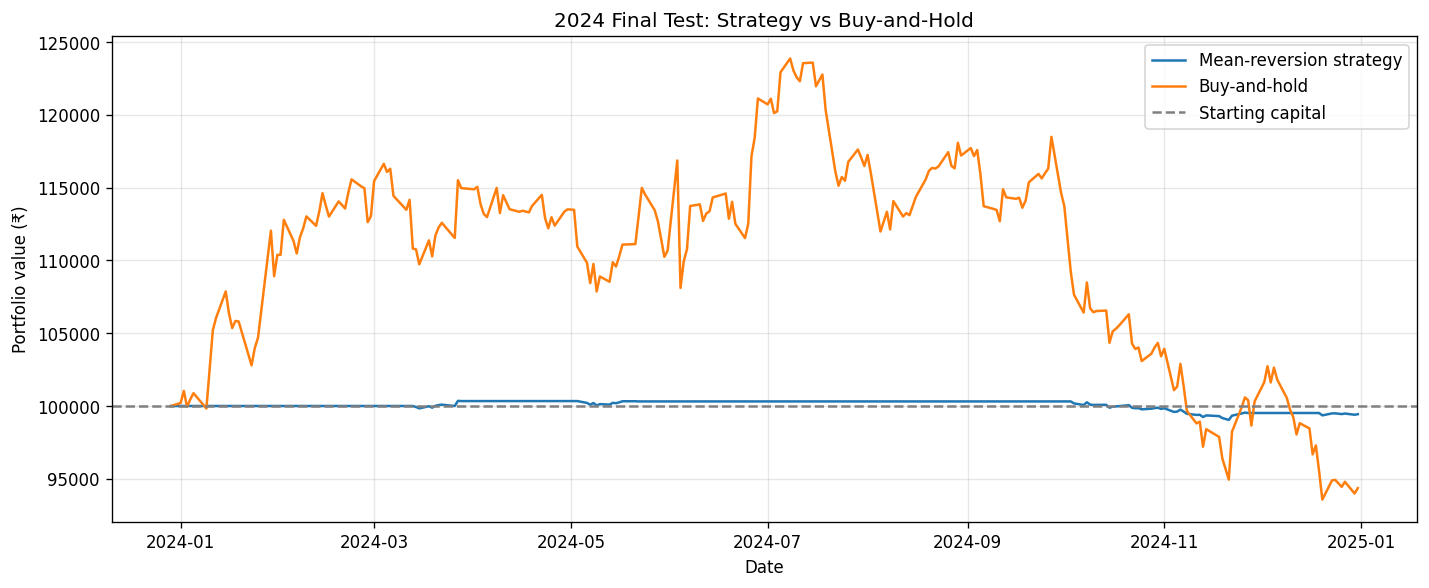

In [16]:
import matplotlib.pyplot as plt

test_close = bt.loc[equity_curve.index, "Close"]
buy_hold_curve = initial_cash * test_close / test_close.iloc[0]

plt.figure(figsize=(12, 5))
plt.plot(equity_curve.index, equity_curve["Equity"], label="Mean-reversion strategy")
plt.plot(buy_hold_curve.index, buy_hold_curve, label="Buy-and-hold")
plt.axhline(initial_cash, color="gray", linestyle="--", label="Starting capital")

plt.title("2024 Final Test: Strategy vs Buy-and-Hold")
plt.xlabel("Date")
plt.ylabel("Portfolio value (₹)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

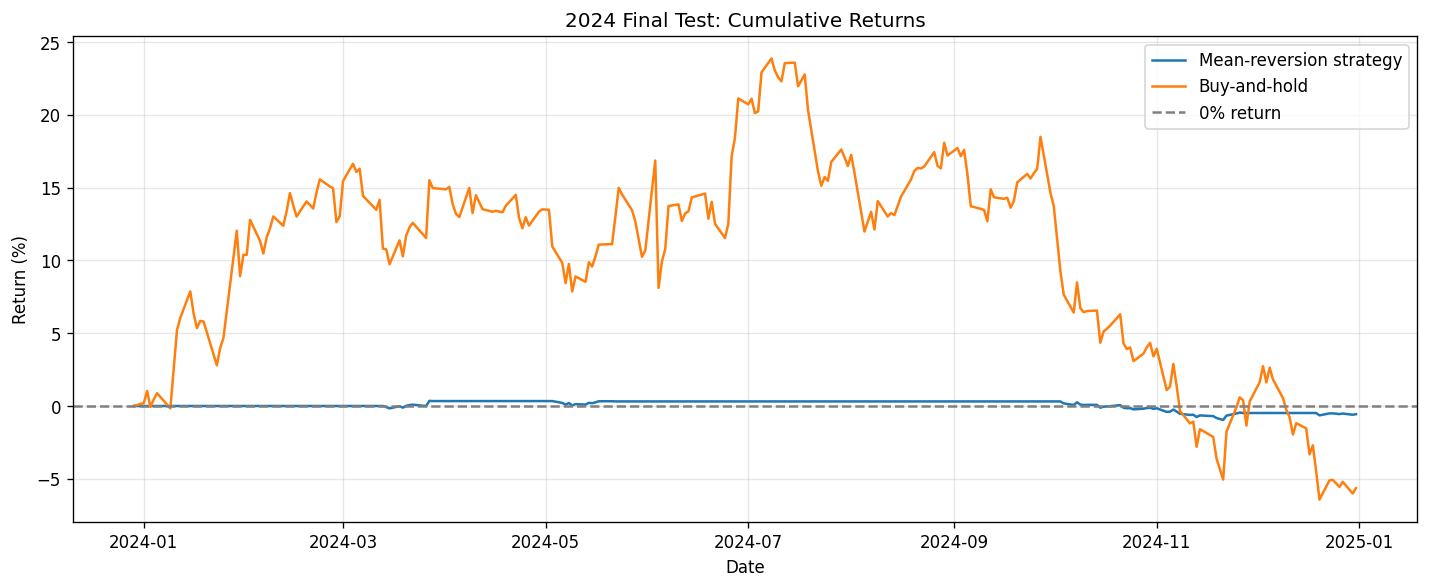

In [17]:
strategy_return_curve = (
    equity_curve["Equity"] / initial_cash - 1
) * 100

buy_hold_return_curve = (
    buy_hold_curve / initial_cash - 1
) * 100

plt.figure(figsize=(12, 5))
plt.plot(
    strategy_return_curve.index,
    strategy_return_curve,
    label="Mean-reversion strategy"
)
plt.plot(
    buy_hold_return_curve.index,
    buy_hold_return_curve,
    label="Buy-and-hold"
)
plt.axhline(0, color="gray", linestyle="--", label="0% return")

plt.title("2024 Final Test: Cumulative Returns")
plt.xlabel("Date")
plt.ylabel("Return (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 2024 Final-Test Interpretation

The mean-reversion strategy ended 2024 with a marked-to-market return of approximately **−0.56%**, compared with **−5.64%** for buy-and-hold. If the remaining position is liquidated using the model’s assumed costs, the strategy return is approximately **−0.58%**.

The strategy held relatively little capital in shares, which helps explain why its equity curve stayed close to zero. It completed three trades and held eight shares at year-end. Its maximum drawdown was approximately **−1.31%**.

The strategy lost less than buy-and-hold during this period, but it did not make a profit. With only three completed trades in one test year, this is limited evidence and does not establish that the strategy will perform similarly in the future.

## Complete metrics, saved plots and technical report
The following code computes development and final-test metrics separately,
exports equity/drawdown/trade-marker plots, tests nearby parameters on
**development data only**, and adds a development-only stop/time-limit
experiment. Baseline rules are unchanged. These extra experiments were added
after the baseline final-test result was observed and do not have a new,
untouched final test.

Daily return ratios use 252-session annualization, a zero risk-free rate and
zero minimum acceptable return. CAGR uses calendar days / 365.25. Undefined
metrics are N/A. Trade metrics exclude open positions; equity includes them.
The full definitions, benchmark rationale and adjusted-price limitations are
included in the generated PDF.


In [18]:
"""Generate the induction report, metrics and charts from adjusted daily OHLCV.
Run: python complete_quant.py --csv data/reliance_prices.csv
Or in Colab: exec(open('complete_quant.py').read()); complete_submission(data)
"""
from pathlib import Path
import json, hashlib, argparse, platform, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

INITIAL = 100_000.0
FRACTION, SLIPPAGE, FEE = .10, .0005, .001
PERIODS = 252

def prepare(data):
    d = data.copy()
    if isinstance(d.columns, pd.MultiIndex):
        d.columns = d.columns.get_level_values(0)
    d.index = pd.to_datetime(d.index)
    if d.index.tz is not None: d.index = d.index.tz_localize(None)
    d = d.sort_index().loc['2016-01-01':'2024-12-31']
    cols = ['Open','High','Low','Close','Volume']
    if d.empty or not set(cols).issubset(d.columns): raise ValueError('Missing OHLCV data')
    if d.index.has_duplicates: raise ValueError('Duplicate dates: inspect source before proceeding')
    d[cols] = d[cols].apply(pd.to_numeric, errors='raise')
    if not np.isfinite(d[cols].to_numpy()).all(): raise ValueError('Non-finite OHLCV values')
    if (d[['Open','High','Low','Close']] <= 0).any().any(): raise ValueError('Non-positive prices')
    if (d['Volume'] < 0).any(): raise ValueError('Negative volume')
    if (d['High'] < d[['Open','Low','Close']].max(axis=1)-1e-6).any() or (d['Low'] > d[['Open','High','Close']].min(axis=1)+1e-6).any():
        raise ValueError('OHLC inconsistency: inspect source')
    return d

def backtest(data, start, end, window=20, threshold=-2., stop=None, max_hold=None):
    """Close-based decisions filled at next Open. Optional stop is NOT intraday."""
    d = data.loc[:end].copy()  # Never include dates after the evaluated period.
    std = d.Close.rolling(window).std(ddof=1).replace(0,np.nan)
    d['Z'] = (d.Close-d.Close.rolling(window).mean())/std
    d = d.loc[start:end]
    if len(d)<2: raise ValueError('At least two sessions are required')
    cash, qty, entry, outlay = INITIAL, 0, None, 0.
    rows = [{'Date': d.index[0], 'Equity':cash, 'Cash':cash, 'Shares':0}]
    trades, events = [], []
    for i in range(1,len(d)):
        prev, today = d.iloc[i-1], d.iloc[i]
        reason = None
        if qty:
            held = (i-1)-entry['index']+1
            if stop is not None and prev.Close <= entry['fill']*(1-stop): reason='close-stop'
            elif max_hold is not None and held>=max_hold: reason='holding-limit'
            elif pd.notna(prev.Z) and prev.Z>=0: reason='mean-exit'
            if reason:
                fill = today.Open*(1-SLIPPAGE)
                proceeds = qty*fill*(1-FEE)
                cash += proceeds
                trades.append({'Entry date':entry['date'], 'Exit date':d.index[i], 'Shares':qty,
                               'Entry fill':entry['fill'], 'Exit fill':fill, 'Net P&L':proceeds-outlay,
                               'Holding sessions':i-entry['index'],'Exit reason':reason})
                events.append({'Date':d.index[i],'Side':'SELL','Fill':fill,'Shares':qty,'Reason':reason})
                qty=0; entry=None; outlay=0.
        elif pd.notna(prev.Z) and prev.Z<threshold:
            fill=today.Open*(1+SLIPPAGE)
            qty=int(cash*FRACTION/(fill*(1+FEE)))
            if qty:
                outlay=qty*fill*(1+FEE); cash-=outlay
                entry={'date':d.index[i], 'fill':fill, 'index':i}
                events.append({'Date':d.index[i],'Side':'BUY','Fill':fill,'Shares':qty,'Reason':'z-entry'})
        rows.append({'Date':d.index[i],'Equity':cash+qty*today.Close,'Cash':cash,'Shares':qty})
    eq=pd.DataFrame(rows).set_index('Date')
    eq['Drawdown']=eq.Equity/eq.Equity.cummax()-1
    benchmark=INITIAL*d.Close/d.Close.iloc[0]
    t=pd.DataFrame(trades,columns=['Entry date','Exit date','Shares','Entry fill','Exit fill','Net P&L','Holding sessions','Exit reason'])
    e=pd.DataFrame(events,columns=['Date','Side','Fill','Shares','Reason'])
    liquidation=cash+qty*d.Close.iloc[-1]*(1-SLIPPAGE)*(1-FEE)
    return {'prices':d,'equity':eq,'trades':t,'events':e,'benchmark':benchmark,'liquidation':liquidation}

def metrics(run):
    eq=run['equity']; r=eq.Equity.pct_change().dropna()
    years=(eq.index[-1]-eq.index[0]).days/365.25
    sd=r.std(ddof=1); downside=np.sqrt(np.mean(np.minimum(r,0)**2))
    pnl=run['trades']['Net P&L']; wins=pnl[pnl>0]; losses=pnl[pnl<0]
    return {
      'Cumulative return (%)':100*(eq.Equity.iloc[-1]/INITIAL-1),
      'Annualized return / CAGR (%)':100*((eq.Equity.iloc[-1]/INITIAL)**(1/years)-1) if years>0 else np.nan,
      'Sharpe ratio':np.sqrt(PERIODS)*r.mean()/sd if sd>0 else np.nan,
      'Sortino ratio':np.sqrt(PERIODS)*r.mean()/downside if downside>0 else np.nan,
      'Maximum drawdown (%)':100*eq.Drawdown.min(),
      'Win rate (%)':100*(pnl>0).mean() if len(pnl) else np.nan,
      'Completed trades':len(pnl),
      'Profit factor':wins.sum()/abs(losses.sum()) if len(losses) else np.nan,
      'Average winning trade (INR)':wins.mean(),
      'Average losing trade (INR)':losses.mean(),
      'Maximum winning trade (INR)':wins.max(),
      'Maximum losing trade (INR)':losses.min(),
      'Benchmark return (%)':100*(run['benchmark'].iloc[-1]/INITIAL-1),
      'Average invested exposure (%)':100*(eq.Shares*run['prices'].Close/eq.Equity).mean(),
      'Ending equity (INR)':eq.Equity.iloc[-1],
      'Open adjusted-price units':eq.Shares.iloc[-1],
      'Estimated liquidation return (%)':100*(run['liquidation']/INITIAL-1)
    }

def save_charts(run,label,directory):
    d=run['prices']; eq=run['equity']; bh=run['benchmark']; ev=run['events']
    paths=[]
    for kind in ['equity','drawdown','trades']:
        fig,ax=plt.subplots(figsize=(10,3.4))
        if kind=='equity':
            ax.plot(eq.index,(eq.Equity/INITIAL-1)*100,label='Strategy, after costs',color='#1565a8')
            ax.plot(bh.index,(bh/INITIAL-1)*100,label='Reliance buy-and-hold, before costs',color='#db7a24')
            ax.set_ylabel('Cumulative return (%)')
        elif kind=='drawdown':
            ax.plot(eq.index,eq.Drawdown*100,label='Strategy',color='#1565a8')
            ax.plot(bh.index,(bh/bh.cummax()-1)*100,label='Buy-and-hold',color='#db7a24')
            ax.set_ylabel('Drawdown (%)')
        else:
            ax.plot(d.index,d.Close,label='Adjusted close',color='#50677f',linewidth=.9)
            for side,marker,color in [('BUY','^','#168045'),('SELL','v','#c33141')]:
                e=ev.loc[ev.Side==side]
                ax.scatter(e.Date,e.Fill,marker=marker,color=color,s=40,label=side+' at adjusted Open + slippage',zorder=3)
            ax.set_ylabel('Adjusted price (INR)')
        ax.set_title(label+' | '+kind.capitalize());ax.set_xlabel('Date');ax.grid(alpha=.2);ax.legend(fontsize=8)
        fig.tight_layout();path=directory/(label.split()[0].lower()+'_'+kind+'.png')
        fig.savefig(path,dpi=180);plt.close(fig);paths.append(path)
    return paths

def fmt(v):
    return 'N/A' if pd.isna(v) or not np.isfinite(v) else f'{v:,.2f}'

def create_report(out, runs, table, sensitivity, regimes, risk, data, metadata):
    from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image, PageBreak
    from reportlab.lib.styles import getSampleStyleSheet
    from reportlab.lib import colors
    from reportlab.lib.enums import TA_LEFT
    from xml.sax.saxutils import escape
    styles=getSampleStyleSheet()
    styles['BodyText'].fontSize=9;styles['BodyText'].leading=12
    styles['Heading1'].fontSize=18;styles['Heading1'].textColor=colors.HexColor('#163a5f')
    story=[]
    def p(text):story.append(Paragraph(escape(text),styles['BodyText']));story.append(Spacer(1,7))
    def h(text):story.append(Paragraph(escape(text),styles['Heading1']));story.append(Spacer(1,8))
    def chart(path):story.append(Image(str(path),width=475,height=161.5));story.append(Spacer(1,6))
    def tbl(rows,widths):
        wrapped=[[Paragraph(escape(str(c)),styles['BodyText']) for c in row] for row in rows]
        t=Table(wrapped,colWidths=widths,repeatRows=1)
        t.setStyle(TableStyle([('BACKGROUND',(0,0),(-1,0),colors.HexColor('#e7eef5')),('VALIGN',(0,0),(-1,-1),'TOP'),('BOTTOMPADDING',(0,0),(-1,-1),5),('TOPPADDING',(0,0),(-1,-1),4),('LINEBELOW',(0,0),(-1,0),.6,colors.HexColor('#163a5f')),('ROWBACKGROUNDS',(0,1),(-1,-1),[colors.white,colors.HexColor('#f7f9fb')])]))
        story.append(t);story.append(Spacer(1,8))
    test=table['Final test 2024'];dev=table['Development 2016-2022']
    h('Reliance: testing a mean-reversion idea')
    p('CFA Club, IIT Indore | Finance & Quant, Track 1 | Adrij Sarkar')
    p('Hypothesis: a large negative deviation from a recent average may be followed by a rebound. A 20-session mean and a -2 entry threshold provide a simple, interpretable starting rule. They are fixed baseline choices, not statistically proven optimal values. Stock-price mean reversion is a hypothesis to test, not an assumed property.')
    p('Reliance was selected as a widely traded Indian equity with a long daily price history. Daily OHLCV is sufficient to form closing-price signals and model next-session fills. The strategy does not model order-book liquidity or prove that quoted opens were executable.')
    p(f'Data: Yahoo Finance via yfinance, RELIANCE.NS; {len(data):,} sessions from {data.index[0].date()} to {data.index[-1].date()}. Prices are adjusted OHLC. The download is checked for missing/non-finite values, duplicates, non-positive prices and invalid OHLC ordering; suspicious data cause an error rather than automatic deletion. Extreme returns are retained absent evidence of a data error.')
    tbl([['Rule','Baseline specification'],['Signal','Z = (Close - trailing 20-session mean) / sample standard deviation (ddof=1).'],['Entry / exit','Buy when previous Z < -2; sell when previous Z >= 0; fill at current Open.'],['Capital / sizing','INR 100,000; 10% of available cash including entry fee; integer adjusted-price units; one long position; no leverage.'],['Costs','0.05% adverse slippage plus 0.10% fee on each buy and sell. Idle cash earns zero.'],['Risk control','Position-size cap only; baseline has no stop or time limit. It can hold a losing position indefinitely. A separate development-only experiment adds explicit exit controls.']],[90,385])
    p(f'Final-test outcome: {fmt(test["Cumulative return (%)"])}% strategy return versus {fmt(test["Benchmark return (%)"])}% buy-and-hold, with {int(test["Completed trades"])} completed trades. Lower exposure helps explain lower drawdown; this is not evidence of superior risk-adjusted performance across markets.')
    story.append(PageBreak());h('Performance metrics and conventions')
    p('Development: first session of 2016 through the last session of 2022. Final test: 29 December 2023 baseline through 31 December 2024. Each run starts flat with INR 100,000. Prior prices supply trailing indicators, but all order decisions use the preceding session only.')
    rows=[['Metric','Development','Final test']]+[[idx,fmt(row.iloc[0]),fmt(row.iloc[1])] for idx,row in table.iterrows()]
    tbl(rows,[265,105,105])
    p('Returns are daily close-to-close portfolio returns, including idle cash and simulated trading costs. CAGR uses actual elapsed days / 365.25. Sharpe = sqrt(252) x mean(daily return) / sample standard deviation. Risk-free rate is assumed 0% annually. Sortino uses the same numerator and the root mean square of min(daily return, 0) over ALL daily observations; the minimum acceptable return is 0%.')
    p('Trade statistics use completed trades only and net P&L after entry/exit costs. Open-position gains/losses enter equity metrics, but not completed-trade statistics. Loss amounts are negative. N/A denotes no applicable wins/losses/trades, or a zero risk denominator; profit factor is N/A without any losing trades. Estimated liquidation is a separate last-close scenario, not a counted strategy exit.')
    story.append(PageBreak());h('Development behaviour and validation')
    chart(out/'figures/development_equity.png');chart(out/'figures/development_drawdown.png')
    p(f'Development strategy return is {fmt(dev["Cumulative return (%)"])}%, compared with {fmt(dev["Benchmark return (%)"])}% for the benchmark. Average invested exposure is {fmt(dev["Average invested exposure (%)"])}%; interpreting the drawdown without this exposure would overstate the evidence for risk control.')
    p(f'Validation is a slice of a continuous 2016-2023 run: {metadata["validation"]["Return (%)"]:.2f}% strategy return, {metadata["validation"]["Benchmark (%)"]:.2f}% benchmark return and {metadata["validation"]["Drawdown (%)"]:.2f}% drawdown, with {metadata["validation"]["Completed trades entered in 2023"]} completed trades entered in 2023. This is NOT a reset portfolio. Original exploratory work included validation data, so validation was not fully unseen. The separately labelled 2024 baseline was evaluated after rules were fixed.')
    p('Post-review parameter and risk experiments use development data only. They were added after viewing the baseline final-test outcome and must be described as exploratory. No new variant is claimed to have an untouched 2024 test; further confirmation requires genuinely unseen data.')
    story.append(PageBreak());h('Final test: returns, drawdown and execution')
    chart(out/'figures/final_equity.png');chart(out/'figures/final_drawdown.png');chart(out/'figures/final_trades.png')
    p(f'Final marked equity: INR {fmt(test["Ending equity (INR)"])}. Units still held: {int(test["Open adjusted-price units"])}. Estimated liquidation return: {fmt(test["Estimated liquidation return (%)"])}%. Trade markers include the entry of an unfinished position; there is no fabricated year-end sell.')
    p('Benchmark rationale: holding the same stock isolates whether timing its entries/exits improves on passive ownership. This is a permitted alternative to an index benchmark, but is not a broad-market comparison. The benchmark is a fully invested adjusted-close ratio before costs; the strategy is partly invested and after costs.')
    story.append(PageBreak());h('Development-only robustness checks')
    p(f'Neighbouring returns range from {sensitivity.Return.min():.2f}% to {sensitivity.Return.max():.2f}%, showing sensitivity to the rule. The same development period and cost assumptions are used for every combination below. The original window=20 and entry=-2 remain the baseline regardless of this table. A small grid is a sensitivity diagnostic, not proof of robustness.')
    rows=[['Window','Entry Z','Return %','Max DD %','Trades']]+[[int(r.Window),r.Entry,fmt(r.Return),fmt(r.Drawdown),int(r.Trades)] for r in sensitivity.itertuples()]
    tbl(rows,[65,65,115,115,115])
    p('Market conditions are classified using the PREVIOUS session\'s trailing 60-session stock return: rising above +5%, falling below -5%, sideways otherwise. Unavailable warm-up observations are excluded. Conditional averages combine non-contiguous days and are descriptive, not separate investable backtests.')
    rows=[['Regime','Sessions','Mean daily strategy %','Mean daily benchmark %']]+[[r.Regime,int(r.Sessions),f'{r.StrategyMean:.4f}',f'{r.BenchmarkMean:.4f}'] for r in regimes.itertuples()]
    tbl(rows,[100,65,155,155])
    p('Explicit risk-control experiment: retain sizing and add a 5% loss trigger based on the preceding adjusted close versus entry fill, plus a maximum 20 held sessions. Both exits fill at the NEXT open with costs. A gap can produce a loss greater than 5%; this is not an intraday guaranteed stop.')
    rows=[['Development variant','Return %','Max DD %','Trades']]+[[r.Variant,fmt(r.Return),fmt(r.Drawdown),int(r.Trades)] for r in risk.itertuples()]
    tbl(rows,[205,90,90,90])
    p('The added exits reduced development return and made maximum drawdown worse in this sample. A stop does not automatically improve performance; this experiment is not adopted as the baseline.')
    story.append(PageBreak());h('Limitations, resources and assistance')
    p('Adjusted OHLC makes corporate-action handling consistent within this simplified price simulation, but is not a point-in-time reconstruction of actual share quantities, splits and dividend cash payments. Integer sizing on retrospectively adjusted prices can depend on future adjustment factors. These prices are research units rather than historical executable rupee quotes; a production study should use raw execution prices and explicit action accounting.')
    p('The strategy has one stock, few final-test trades, fixed costs, no interest on cash, no market-impact model, and no baseline stop/time limit. Exposure differs from the benchmark. A high win rate does not imply profitability: infrequent large losses can outweigh small wins. Lower loss than buy-and-hold in one year is not proof of persistent advantage.')
    p('Possible improvements: corporate-action accounting with raw fills; point-in-time data snapshots; development-only stop/time-limit assessment; broader stock universes; exposure-matched and cost-matched benchmarks; and a genuinely new held-out period. Do not retune parameters to the observed 2024 loss.')
    p('Resources actually used for this submission and completion work:')
    for s in SOURCES:p(s)
    p('Assistance acknowledgement: ChatGPT/Codex assisted with explanations, code drafting and debugging, repository review, metrics and chart implementation, and report preparation. The student must review the delivered work, disclose any other resources used, and be able to explain all code and conclusions. This acknowledgement does not claim independent authorship of assisted code.')
    p('Reproducibility: a dated adjusted-price CSV snapshot is included. The output includes a data fingerprint, actual package versions and generated metrics CSVs. Dependencies are listed in requirements.txt. The notebook can use a locally saved adjusted-price CSV or download again from Yahoo; provider revisions can change results. Original analysis cells are retained as an audit trail.')
    p('Data SHA-256: '+metadata['data_sha256'])
    def footer(canvas,doc):
        canvas.setFont('Helvetica',8);canvas.setFillColor(colors.HexColor('#64748b'))
        canvas.drawString(45,28,'CFA induction | Reliance mean reversion | Educational research')
        canvas.drawRightString(550,28,str(doc.page))
    SimpleDocTemplate(str(out/'quant_technical_report.pdf'),title='Reliance Mean-Reversion Backtest',author='Adrij Sarkar (with disclosed ChatGPT/Codex assistance)',pagesize=(595.28,841.89),rightMargin=50,leftMargin=50,topMargin=40,bottomMargin=45).build(story,onFirstPage=footer,onLaterPages=footer)

SOURCES=[
 'CFA Club, IIT Indore. Induction Task 2026, Finance & Quant, pp. 5-8 (user-supplied task PDF).',
 'Yahoo Finance, RELIANCE.NS historical prices: https://finance.yahoo.com/quote/RELIANCE.NS/history/',
 'yfinance download API: https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html',
 'pandas project (data frames and rolling calculations): https://pandas.pydata.org/docs/',
 'NumPy project (numerical calculations): https://numpy.org/doc/',
 'Matplotlib project (plots): https://matplotlib.org/stable/',
 'ReportLab project (PDF generation): https://docs.reportlab.com/',
 'Original student repository: https://github.com/adrijsarkar07/CFA-INDUCTION'
]

def complete_submission(data, output_dir='outputs'):
    data=prepare(data);out=Path(output_dir);(out/'figures').mkdir(parents=True,exist_ok=True)
    runs={'Development 2016-2022':backtest(data,'2016-01-01','2022-12-31'),
          'Final test 2024':backtest(data,'2023-12-29','2024-12-31')}
    table=pd.DataFrame({name:metrics(run) for name,run in runs.items()})
    table.to_csv(out/'performance_metrics.csv',na_rep='N/A')
    for name,run in runs.items():
        stem=name.split()[0].lower()
        run['equity'].to_csv(out/(stem+'_equity.csv'))
        run['trades'].to_csv(out/(stem+'_trades.csv'),index=False)
        run['events'].to_csv(out/(stem+'_events.csv'),index=False)
        save_charts(run,name,out/'figures')
    sensitivity=[]
    for w in [15,20,25]:
        for threshold in [-2.5,-2.,-1.5]:
            m=metrics(backtest(data,'2016-01-01','2022-12-31',window=w,threshold=threshold))
            sensitivity.append({'Window':w,'Entry':threshold,'Return':m['Cumulative return (%)'],'Drawdown':m['Maximum drawdown (%)'],'Trades':m['Completed trades']})
    sensitivity=pd.DataFrame(sensitivity);sensitivity.to_csv(out/'development_sensitivity.csv',index=False)
    dev=runs['Development 2016-2022'];trend=dev['prices'].Close.pct_change(60).shift(1)
    states=pd.Series(np.select([trend>.05,trend<-.05],['Rising','Falling'],default='Sideways'),index=trend.index)
    frame=pd.DataFrame({'Regime':states,'StrategyMean':dev['equity'].Equity.pct_change()*100,'BenchmarkMean':dev['benchmark'].pct_change()*100}).loc[trend.notna()].dropna()
    regimes=frame.groupby('Regime').agg(Sessions=('StrategyMean','size'),StrategyMean=('StrategyMean','mean'),BenchmarkMean=('BenchmarkMean','mean')).reset_index()
    regimes.to_csv(out/'development_regimes.csv',index=False)
    controlled=backtest(data,'2016-01-01','2022-12-31',stop=.05,max_hold=20)
    risk=[]
    for label,run in [('Baseline: sizing only',dev),('5% close-stop + 20 sessions',controlled)]:
        m=metrics(run);risk.append({'Variant':label,'Return':m['Cumulative return (%)'],'Drawdown':m['Maximum drawdown (%)'],'Trades':m['Completed trades']})
    risk=pd.DataFrame(risk);risk.to_csv(out/'development_risk_experiment.csv',index=False)
    controlled['trades'].to_csv(out/'development_risk_trades.csv',index=False)
    continuous=backtest(data,'2016-01-01','2023-12-31')
    ve=continuous['equity'].loc['2023', 'Equity']; vc=continuous['prices'].loc[ve.index,'Close']
    vt=continuous['trades']; vn=int((pd.to_datetime(vt['Entry date']).dt.year==2023).sum())
    val={'Return (%)':100*(ve.iloc[-1]/ve.iloc[0]-1),'Benchmark (%)':100*(vc.iloc[-1]/vc.iloc[0]-1),'Drawdown (%)':100*(ve/ve.cummax()-1).min(),'Completed trades entered in 2023':vn}
    pd.Series(val).to_csv(out/'validation_slice.csv',header=['Value'])
    metadata={'validation':val,'generated_utc':pd.Timestamp.now(tz='UTC').isoformat(),'data_sha256':hashlib.sha256(data.to_csv().encode()).hexdigest(),'rows':len(data),'first_date':str(data.index.min()),'last_date':str(data.index.max()),'python':platform.python_version(),'packages':{}}
    for package in ['pandas','numpy','matplotlib','yfinance','reportlab']:
        try:metadata['packages'][package]=importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:pass
    (out/'run_metadata.json').write_text(json.dumps(metadata,indent=2))
    create_report(out,runs,table,sensitivity,regimes,risk,data,metadata)
    print(table.to_string(na_rep='N/A',float_format=lambda x:f'{x:,.4f}'))
    print('\nReport, charts, trade logs and metrics saved to:',out.resolve())
    return table,runs



                                  Development 2016-2022  Final test 2024
Cumulative return (%)                            2.7037          -0.5639
Annualized return / CAGR (%)                     0.3821          -0.5597
Sharpe ratio                                     0.2787          -0.6055
Sortino ratio                                    0.4007          -0.8507
Maximum drawdown (%)                            -3.3181          -1.3054
Win rate (%)                                    75.0000          33.3333
Completed trades                                24.0000           3.0000
Profit factor                                    1.9713           0.4120
Average winning trade (INR)                    293.1011         337.3648
Average losing trade (INR)                    -446.0605        -409.4357
Maximum winning trade (INR)                    714.1098         337.3648
Maximum losing trade (INR)                  -1,685.4636        -794.4378
Benchmark return (%)                           428.

,Development 2016-2022,Final test 2024
Cumulative return (%),2.7037,-0.5639
Annualized return / CAGR (%),0.3821,-0.5597
Sharpe ratio,0.2787,-0.6055
Sortino ratio,0.4007,-0.8507
Maximum drawdown (%),-3.3181,-1.3054
Win rate (%),75.0000,33.3333
Completed trades,24.0000,3.0000
Profit factor,1.9713,0.4120
Average winning trade (INR),293.1011,337.3648
Average losing trade (INR),-446.0605,-409.4357


,Window,Entry,Return,Drawdown,Trades
0,15,-2.5,1.874051,-2.352811,7
1,15,-2.0,5.766962,-3.457694,37
2,15,-1.5,8.401218,-3.935746,53
3,20,-2.5,1.090133,-3.335610,13
4,20,-2.0,2.703698,-3.318065,24
5,20,-1.5,3.872999,-3.508268,41
6,25,-2.5,0.478122,-3.322070,10
7,25,-2.0,3.976956,-3.488668,23
8,25,-1.5,3.004935,-3.493828,32


,Regime,Sessions,StrategyMean,BenchmarkMean
0,Falling,271,0.008815,0.316419
1,Rising,806,0.001135,0.129688
2,Sideways,592,-0.001457,0.001777


,Variant,Return,Drawdown,Trades
0,Baseline: sizing only,2.703698,-3.318065,24
1,5% close-stop + 20 sessions,1.562963,-3.947628,28


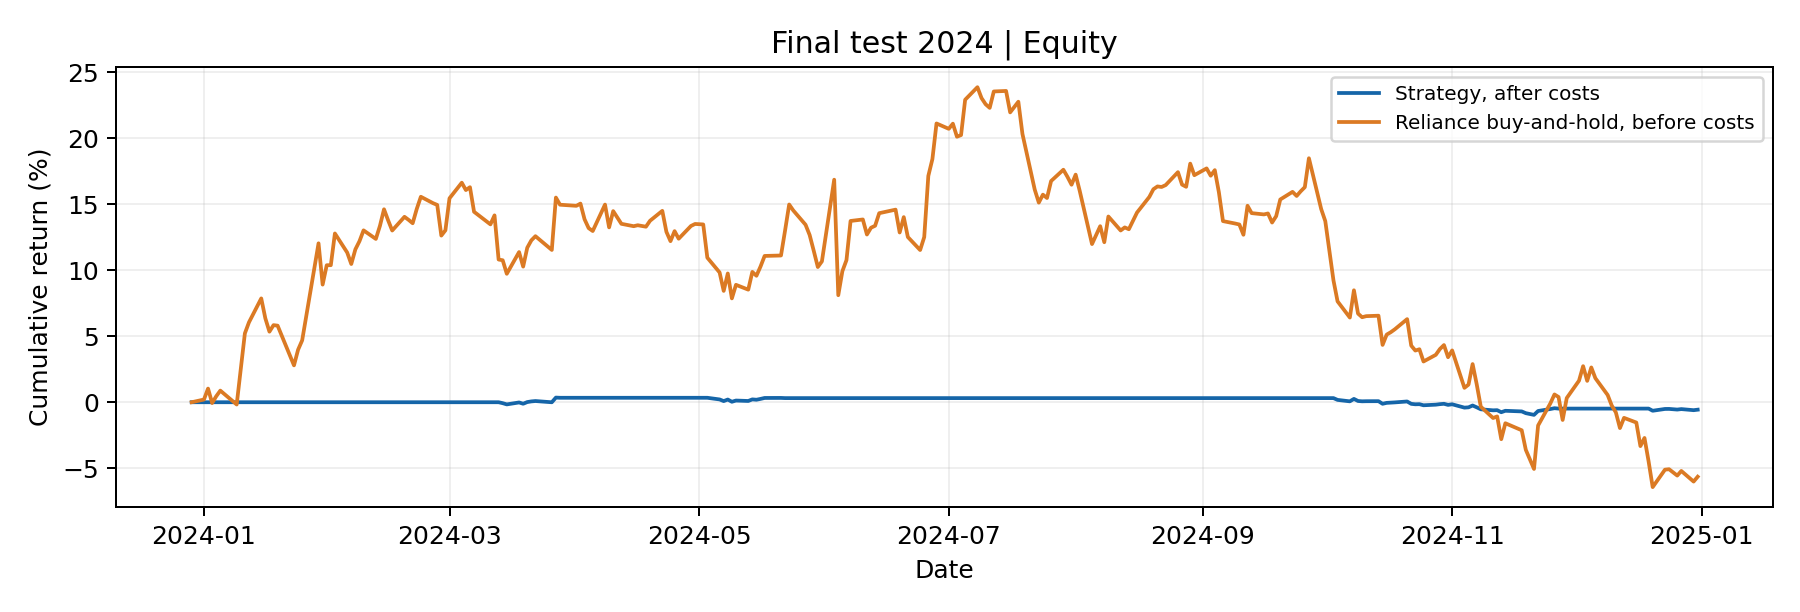

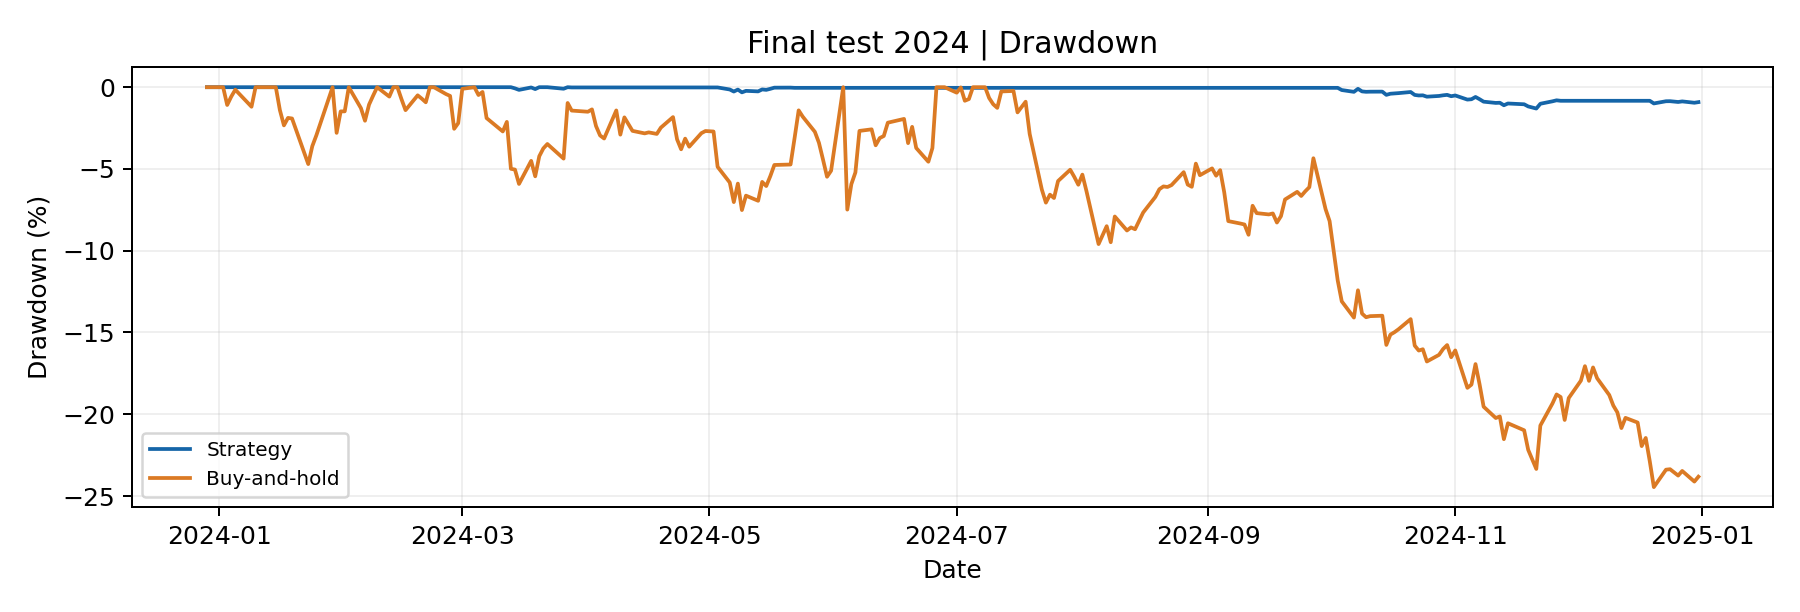

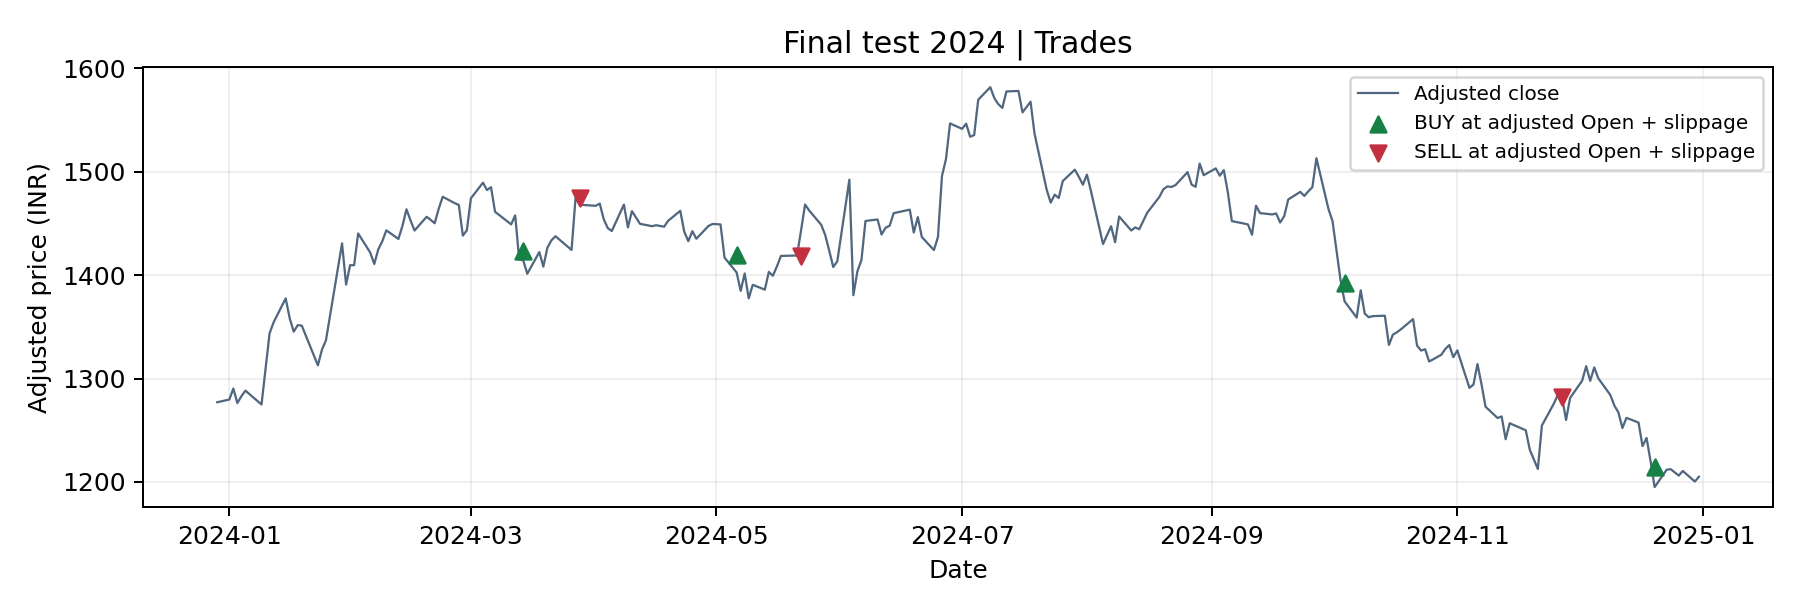

In [19]:
from IPython.display import display, Image
output_dir = project_root / 'outputs'
performance_table, evaluated_runs = complete_submission(data, output_dir)
display(performance_table.round(4))
for name in ['development_sensitivity.csv', 'development_regimes.csv', 'development_risk_experiment.csv']:
    print(name)
    display(pd.read_csv(output_dir / name))
for name in ['final_equity.png', 'final_drawdown.png', 'final_trades.png']:
    display(Image(filename=str(output_dir / 'figures' / name)))